# Vantor Legion data tracking: site request and supplemental tasking vs CSDA

Two questions:

1. **Site request** (`Legion_20260914` tab of the *Evaluation Site Requests* Google Sheet): at each requested site, how many
   Legion acquisitions in CSDA STAC meet the site's requirements, against its min / ideal number? Counted over all dates
   and split into **archive** (acquired before the request date) and **new** (since).
2. **Supplemental tasking** (`VantorLegion_Supp` tab of the On-Ramp 2 order tracking xlsx): which of the 3-day tasking
   windows at WLEF and Valencia have an acquisition in CSDA STAC or on ADAPT?
3. **Pipeline**: since the request, how many Legion collects has Vantor made at the sites (Vantor Discovery API), and how
   many of those has CSDA delivered yet?
4. **Summary since September** (section 9): what is new in CSDA STAC since `SINCE`, and what Vantor has collected
   that is not in CSDA STAC yet, as short conclusions and the notes for the timeline.

| Step | Output |
|---|---|
| 1. Read the site request (live from the Google Sheet) | `request`: one row per site with its requirements |
| 2. Read the supplemental tasking tab | `windows`: one row per tasking order (OrderID) and its window |
| 3. Search CSDA STAC | `res.gdf`: every `maxar-legion` product at the requested sites since `LEGION_START` (fresh search, no cache); monthly heatmap of acquisitions per site |
| 4. Acquisitions vs requirements | `acqs`: one row per CSDA acquisition (MS + PAN products of one collect counted once), with the checks; monthly heatmap of those meeting the requirements |
| 5. On ADAPT | `local`: Legion acquisitions at the sites in the local footprints; `acqs.on_adapt` |
| 6. Site request summary | `request_summary`: per site, acquisitions meeting the requirements (archive / new) vs min / ideal |
| 7. Supplemental windows | `windows_summary`: windows with data per site |
| 8. Vantor archive vs CSDA | `vantor_summary`: Legion collects in Vantor's own archive since the request, and how many are in CSDA yet; the notes for `timeline.ipynb` |

**Requirement checks** (from the request tab):
- **View angle**: `max_view_angle` against the acquisition's off-nadir angle (`view:off_nadir`).
- **Cloud**: STAC gives cloud cover for the whole scene only. A scene within the AOI limit passes. A scene above it is
  marked *check AOI* (`cloud_ok` empty) rather than failed, because the AOI itself may still be clear.
  (CSDA stores Legion cloud cover as a 0-1 fraction; `multistac` converts it to percent.)
- **Product**: MS requested -> the acquisition needs an MS product (pansharpened only does not count).
- **TOA / SR**: not in CSDA's STAC metadata, so not checked here.
- **'1 per sensor'** (e.g. Baotou): the count is the number of Legion sensors with at least one acquisition meeting the
  requirements, out of `LEGION_SENSORS`.

Vantor's archive (section 8) needs the `[Vantor_STAC_API]` key in `credentials.ini` (see `lib/stac_providers.yaml`).

Library: `lib/order_tracking.py` (`read_legion_request`, `read_vantor_supp`), `lib/multistac.py` (search).

In [1]:
import sys
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import os
import importlib
import pandas as pd
import multistac, multistac_plots, order_tracking
for m in (multistac, multistac_plots, order_tracking):
    importlib.reload(m)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 200)

## Parameters

In [2]:
# Site request: 'Evaluation Site Requests' Google Sheet, tab Legion_20260914 (gid from the tab's URL)
REQUEST_SHEET_ID = '16VopHRqlt5qbl4HgZdkVLUIHLVi9lZWPLJMY-QWsJ8g'
REQUEST_GID = 226856298
REQUEST_DATE = '2026-09-14'                   # acquisitions before this are archive, on or after are new
SINCE = '2026-09-01'                          # section 9 summary: images acquired on or after this date
REQUEST_SITES = '/home/pmontesa/code/csda_summaries/sites/csda_sites_aoi_Vantor_Legion_20260922.geojson'
SITE_NAME_FIELD = 'Site Name'
SITE_ALIASES = {}   # sheet name -> name in the sites file
LEGION_SENSORS = ['LG01', 'LG02', 'LG03', 'LG04', 'LG05', 'LG06']
CLOUD_COVER_MAX = None                        # max scene cloud cover (%) for both searches; None = no limit

# Supplemental tasking windows: On-Ramp 2 order tracking workbook
TRACKING_XLSX = '/home/pmontesa/code/csda_summaries/sites/OnRamp2_OrderTracking_August2026.xlsx'
TRACKING_SHEET = 'VantorLegion_Supp'

PROVIDERS = {'csda': ['maxar-legion']}
VANTOR_PROVIDERS = {'vantor': [s.lower() for s in LEGION_SENSORS]}   # Vantor Discovery API: Legion collections lg01-lg06
LEGION_START = '2024-01-01'                   # before the first Legion launch (May 2024)
END = pd.Timestamp.today().strftime('%Y-%m-%d')

LOCAL_FOOTPRINTS = '/explore/nobackup/projects/CSDA_eval/footprints/footprints_CSDA_eval_ACQUISITIONS_unique_latest.csv'   # one row per local acquisition
MATCH_SECONDS = 120                           # CSDA acquisition = local acquisition: same site and sensor, times this close

## 1. The Legion site request

Read live from the Google Sheet (shared as 'anyone with the link'), so edits to the tab show up on the next run.

In [3]:
request = order_tracking.read_legion_request(order_tracking.google_sheet_csv_url(REQUEST_SHEET_ID, REQUEST_GID),
                                             site_aliases=SITE_ALIASES)
print(f"{len(request)} requested sites")
request[['site_name', 'eval_category', 'max_view_angle', 'max_cloud_pct_aoi', 'max_cloud_pct_scene', 'pan', 'ms', 'toa',
         'sr', 'min_acqs', 'min_per_sensor', 'ideal_acqs', 'ideal_note'] + LEGION_SENSORS]

9 requested sites


,site_name,eval_category,max_view_angle,max_cloud_pct_aoi,max_cloud_pct_scene,pan,ms,toa,sr,min_acqs,min_per_sensor,ideal_acqs,ideal_note,LG01,LG02,LG03,LG04,LG05,LG06
0,Baotou,Radiometric & Geometric,15.0,0.0,NaN,False,True,True,False,1,True,<NA>,,?,?,?,?,?,?
1,Gobabeb,Radiometric,10.0,NaN,NaN,False,True,True,False,5,False,10,,?,?,?,?,?,?
2,La Crau,Radiometric & Geometric,10.0,NaN,NaN,False,True,True,False,<NA>,False,<NA>,,?,?,?,?,?,?
3,PICS Libya-4,Radiometric,NaN,0.0,NaN,False,True,True,False,5,False,10,*,?,?,?,?,?,?
4,Railroad Valley,Radiometric,10.0,NaN,NaN,False,True,True,False,5,False,10,,?,?,?,?,?,?
5,Sioux Falls,Geometric,10.0,NaN,NaN,False,True,True,False,5,False,10,,?,?,?,?,?,?
6,Valencia,Radiometric,10.0,NaN,NaN,False,True,False,True,3,False,15,,?,?,?,?,?,?
7,Golmud,Radiometric,10.0,NaN,NaN,False,True,True,False,5,False,10,,?,?,?,?,?,?
8,WLEF,Radiometric,10.0,NaN,NaN,False,True,False,True,3,False,15,,?,?,?,?,?,?


## 2. The supplemental tasking windows

One row per tasking order. `window` numbers the orders of a site in sheet order (1 = first window). Each End is the next
window's Start, so a window is `[Start, End)`.

In [4]:
windows = order_tracking.read_vantor_supp(TRACKING_XLSX, TRACKING_SHEET, site_aliases=SITE_ALIASES)
SUPP_START = windows.window_start.min()
print(f"{len(windows)} tasking orders at {windows.site_name.nunique()} sites, "
      f"windows {SUPP_START:%Y-%m-%d} to {windows.window_end.max():%Y-%m-%d}")
print('Filled in the sheet so far:',
      {c: int(windows[c].notna().sum()) for c in ['catalog_id', 'order_date', 'date_received', 'toa_radiance', 'surface_refl']})
windows.groupby('site_name').agg(orders=('order_id', 'size'), first_window=('window_start', 'min'),
                                 last_window_end=('window_end', 'max'), min_scenes=('min_scenes', 'first'),
                                 ideal_scenes=('ideal_scenes', 'first'), eval_category=('eval_category', 'first'))

30 tasking orders at 2 sites, windows 2026-09-17 to 2026-11-01
Filled in the sheet so far: {'catalog_id': 0, 'order_date': 0, 'date_received': 0, 'toa_radiance': 0, 'surface_refl': 0}


,orders,first_window,last_window_end,min_scenes,ideal_scenes,eval_category
site_name,,,,,,
Valencia,15,2026-09-17 00:00:00+00:00,2026-11-01 00:00:00+00:00,5,15,radiometric
WLEF,15,2026-09-17 00:00:00+00:00,2026-11-01 00:00:00+00:00,5,15,radiometric


## 3. Search CSDA STAC at the requested sites

In [5]:
sites = multistac.load_sites(REQUEST_SITES, site_name_field=SITE_NAME_FIELD)
wanted = set(request.site_name) | set(windows.site_name)
missing = sorted(wanted - set(sites.site_name))
if missing:
    print('Sites not in the sites file (add to SITE_ALIASES):', missing)
sites = sites[sites.site_name.isin(wanted)]
print(len(sites), 'sites:', ', '.join(sites.site_name))

9 sites: Baotou, Gobabeb, La Crau, PICS Libya-4, Railroad Valley, Sioux Falls, Valencia, Golmud, WLEF


In [6]:
%%time
res = multistac.search(sites, LEGION_START, END, PROVIDERS, cloud_cover_max=CLOUD_COVER_MAX)   # no cache_dir: always a fresh search, so new deliveries are found
print(res)
res.log[res.log.status == 'failed']

searches:   0%|          | 0/9 [00:00<?, ?it/s]

searches:  11%|█         | 1/9 [00:00<00:02,  3.39it/s]

searches:  44%|████▍     | 4/9 [00:00<00:00, 10.54it/s]

searches:  67%|██████▋   | 6/9 [00:00<00:00,  9.72it/s]

searches: 100%|██████████| 9/9 [00:00<00:00, 12.75it/s]

searches: 100%|██████████| 9/9 [00:00<00:00, 10.92it/s]

SearchResult(189 rows, 189 unique items, 0 failed tasks)
CPU times: user 279 ms, sys: 47.4 ms, total: 326 ms
Wall time: 1.4 s


,provider,collection,site_name,interval,status,count,matched,server_filters,error,seconds


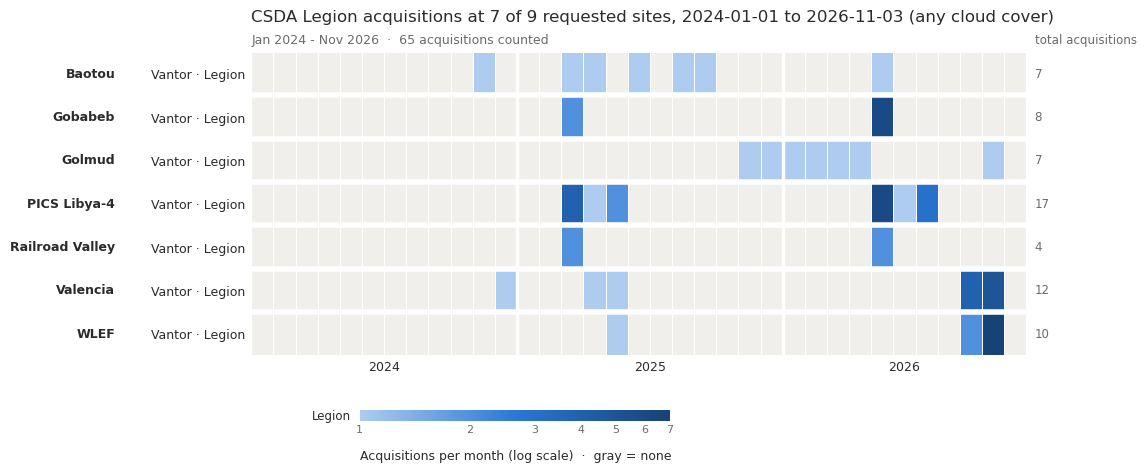

In [7]:
# Acquisitions: how often each site was imaged (products of one collect counted once)
HEATMAP_ROWS = ['site_name', 'affiliation', 'constellation']
cloud_txt = 'any cloud cover' if CLOUD_COVER_MAX is None else f'cloud cover <= {CLOUD_COVER_MAX}%'
multistac_plots.plot_month_heatmap(res.by_month(HEATMAP_ROWS, count='acquisitions'), color_by='constellation', max_rows=None,
                                   start=LEGION_START[:7], end=END[:7],
                                   title=f'CSDA Legion acquisitions at {res.gdf.site_name.nunique()} of {len(sites)} requested sites, '
                                         f'{LEGION_START} to {END} ({cloud_txt})');

## 4. CSDA acquisitions vs the site requirements

One row per site and acquisition. `new` = acquired on or after `REQUEST_DATE`. `view_ok`, `ms_ok`, `cloud_ok` are the
checks (empty `cloud_ok` = scene above the AOI cloud limit: check the AOI); `meets` = all three.

In [8]:
g = res.gdf.copy()
g['datetime'] = pd.to_datetime(g.datetime, utc=True, format='mixed')
join = lambda s: ', '.join(sorted(s.dropna().astype(str).unique()))
acqs = (g.groupby(['site_name', 'acquisition_id'], as_index=False)
         .agg(csda_time=('datetime', 'min'), sensor=('sensor', 'first'), n_products=('id', 'nunique'),
              spectral_modes=('spectral_mode', join), processing_levels=('processing_level', join),
              off_nadir=('off_nadir', 'max'), cloud_pct=('cloud_cover', 'max')))
acqs = acqs[acqs.csda_time >= pd.Timestamp(LEGION_START, tz='UTC')]   # STAC date ranges can reach back further
acqs['new'] = acqs.csda_time >= pd.Timestamp(REQUEST_DATE, tz='UTC')

req = request.set_index('site_name')

def check_requirements(df):
    # adds view_ok, ms_ok, cloud_ok, meets to a table with site_name, off_nadir, spectral_modes, cloud_pct
    limit = lambda col: df.site_name.map(req[col])
    df['view_ok'] = limit('max_view_angle').isna() | (df.off_nadir <= limit('max_view_angle'))
    df['ms_ok'] = ~limit('ms').fillna(False).astype(bool) | df.spectral_modes.str.contains(r'\bms\b')
    scene_ok = limit('max_cloud_pct_scene').isna() | (df.cloud_pct <= limit('max_cloud_pct_scene'))
    aoi_ok = limit('max_cloud_pct_aoi').isna() | (df.cloud_pct <= limit('max_cloud_pct_aoi'))
    df['cloud_ok'] = pd.array(scene_ok, dtype='boolean')
    df.loc[scene_ok & ~aoi_ok, 'cloud_ok'] = pd.NA                   # scene too cloudy for the AOI limit: check the AOI
    df.loc[~scene_ok, 'cloud_ok'] = False
    df['meets'] = df.view_ok & df.ms_ok & df.cloud_ok
    return df

acqs = check_requirements(acqs).sort_values(['site_name', 'csda_time']).reset_index(drop=True)

print(f"{len(acqs)} CSDA Legion acquisitions at {acqs.site_name.nunique()} sites, {LEGION_START} to {END}: "
      f"{int(acqs.meets.fillna(False).sum())} meet the requirements, {int(acqs.meets.isna().sum())} to check (AOI cloud)")
print('Failing:', {c: int((~acqs[c].fillna(True)).sum()) for c in ['view_ok', 'ms_ok', 'cloud_ok']})
acqs

65 CSDA Legion acquisitions at 7 sites, 2024-01-01 to 2026-11-03: 23 meet the requirements, 1 to check (AOI cloud)
Failing: {'view_ok': 35, 'ms_ok': 6, 'cloud_ok': 0}


,site_name,acquisition_id,csda_time,sensor,n_products,spectral_modes,processing_levels,off_nadir,cloud_pct,new,view_ok,ms_ok,cloud_ok,meets
0,Baotou,LG02_20241120T033559,2024-11-20 03:35:59.871865+00:00,LG02,1,pansharpened,LV3D,7.4,0.0,False,True,False,True,False
1,Baotou,LG02_20250314T033953,2025-03-14 03:39:53.996935+00:00,LG02,1,pansharpened,LV3D,4.4,0.0,False,True,False,True,False
2,Baotou,LG04_20250424T003342,2025-04-24 00:33:42.622158+00:00,LG04,1,pansharpened,LV3D,14.0,0.0,False,True,False,True,False
3,Baotou,LG04_20250603T031825,2025-06-03 03:18:25.871847+00:00,LG04,1,pansharpened,LV3D,13.8,4.4,False,True,False,<NA>,False
4,Baotou,LG05_20250829T022328,2025-08-29 02:23:28.246798+00:00,LG05,1,pansharpened,LV3D,14.0,0.1,False,True,False,<NA>,False
5,Baotou,LG05_20250906T032136,2025-09-06 03:21:36.246792+00:00,LG05,1,pansharpened,LV3D,2.9,0.0,False,True,False,True,False
6,Baotou,LG03_20260503T000140,2026-05-03 00:01:40.621959+00:00,LG03,2,"ms, pan",LV2A,9.4,0.0,False,True,True,True,True
7,Gobabeb,LG01_20250302T091951,2025-03-02 09:19:51.246814+00:00,LG01,2,"ms, pan",LV2A,19.1,0.0,False,False,True,True,False
8,Gobabeb,LG02_20250305T091947,2025-03-05 09:19:47.871806+00:00,LG02,2,"ms, pan",LV2A,11.9,0.0,False,False,True,True,False
9,Gobabeb,LG05_20260502T102455,2026-05-02 10:24:55.496809+00:00,LG05,2,"ms, pan",LV2A,14.9,0.0,False,False,True,True,False


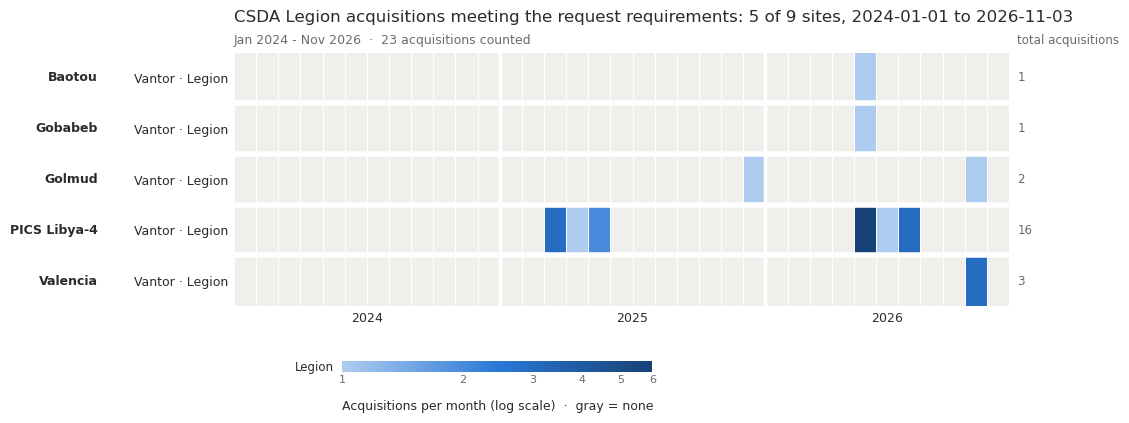

In [9]:
# Acquisitions that meet the site requirements (same layout and months as the plot above)
meets_gdf = g.merge(acqs.loc[acqs.meets.fillna(False), ['site_name', 'acquisition_id']])
multistac_plots.plot_month_heatmap(multistac.month_table(meets_gdf, HEATMAP_ROWS, count='acquisitions'), color_by='constellation',
                                   max_rows=None, start=LEGION_START[:7], end=END[:7],
                                   title=f'CSDA Legion acquisitions meeting the request requirements: {acqs.loc[acqs.meets.fillna(False)].site_name.nunique()} '
                                         f'of {len(sites)} sites, {LEGION_START} to {END}');

## 5. On ADAPT

Legion acquisitions at the requested sites in the local footprints (`LOCAL_FOOTPRINTS`, written by
`footprint_CSDA_eval_all_data.ipynb`; rerun that notebook after a download so this stays current). A CSDA acquisition
is on ADAPT if a local acquisition of the same site and sensor is within `MATCH_SECONDS`.

In [10]:
local = pd.read_csv(LOCAL_FOOTPRINTS, usecols=['affiliation', 'constellation', 'sensor', 'acquisition_id',
                                               'acquisition_datetime', 'sites', 'metadata_path'])
local = local[local.constellation.eq('Legion')].copy()
local['acq_time'] = pd.to_datetime(local.acquisition_datetime, utc=True, format='mixed')
local = local.assign(site_name=local.sites.str.split(r',\s*')).explode('site_name')
local = local[local.site_name.isin(wanted)].drop_duplicates(['site_name', 'acquisition_id'])

key = lambda t: t.astype('datetime64[ns, UTC]')
matched = pd.merge_asof(acqs[['site_name', 'sensor', 'acquisition_id', 'csda_time']].assign(t=key(acqs.csda_time)).sort_values('t'),
                        local[['site_name', 'sensor', 'acquisition_id', 'acq_time']].rename(columns={'acquisition_id': 'local_id'})
                            .assign(t=key(local.acq_time)).sort_values('t'),
                        on='t', by=['site_name', 'sensor'], direction='nearest',
                        tolerance=pd.Timedelta(seconds=MATCH_SECONDS))
acqs = acqs.drop(columns=['local_id', 'on_adapt'], errors='ignore').merge(matched[['site_name', 'acquisition_id', 'local_id']], how='left')
acqs['on_adapt'] = acqs.local_id.notna()
print(f"{local.acquisition_id.nunique()} Legion acquisitions on ADAPT at the requested sites; "
      f"{int(acqs.on_adapt.sum())} of {len(acqs)} CSDA acquisitions found there "
      f"(local footprints: {pd.Timestamp(os.path.getmtime(LOCAL_FOOTPRINTS), unit='s'):%Y-%m-%d})")
local.groupby('site_name').agg(acquisitions=('acquisition_id', 'nunique'), first=('acq_time', 'min'), last=('acq_time', 'max'))

17 Legion acquisitions on ADAPT at the requested sites; 17 of 65 CSDA acquisitions found there (local footprints: 2026-10-29)


,acquisitions,first,last
site_name,,,
Baotou,6,2024-11-20 03:35:59+00:00,2025-09-06 03:21:36+00:00
PICS Libya-4,7,2025-03-02 09:06:41+00:00,2025-05-27 11:53:51+00:00
Valencia,3,2024-12-14 10:53:06+00:00,2025-05-16 16:28:50+00:00
WLEF,1,2025-05-31 20:04:19+00:00,2025-05-31 20:04:19+00:00


## 6. Site request summary

Per site: acquisitions in CSDA, those meeting the requirements (all / archive / new), how many of those are on ADAPT,
and whether the count reaches the sheet's min / ideal. For '1 per sensor' sites the count is the number of sensors
(`LEGION_SENSORS`) with at least one acquisition meeting the requirements.

In [11]:
ok = acqs[acqs.meets.fillna(False)]
by_site = lambda df: df.groupby('site_name')
request_summary = request[['site_name', 'eval_category', 'max_view_angle', 'max_cloud_pct_aoi', 'min_acqs', 'min_per_sensor',
                           'ideal_acqs', 'ideal_per_sensor']].set_index('site_name')
request_summary['csda_acqs'] = by_site(acqs).size()
request_summary['meet_reqs'] = by_site(ok).size()
request_summary['meet_archive'] = by_site(ok[~ok.new]).size()
request_summary['meet_new'] = by_site(ok[ok.new]).size()
request_summary['to_check_aoi_cloud'] = by_site(acqs[acqs.meets.isna()]).size()
request_summary['meet_on_adapt'] = by_site(ok[ok.on_adapt]).size()
request_summary['sensors_meeting'] = by_site(ok).sensor.nunique()
request_summary['last_acq'] = by_site(acqs).csda_time.max().dt.strftime('%Y-%m-%d')
request_summary = request_summary.fillna({c: 0 for c in ['csda_acqs', 'meet_reqs', 'meet_archive', 'meet_new',
                                                          'to_check_aoi_cloud', 'meet_on_adapt', 'sensors_meeting']})
for kind in ('min', 'ideal'):
    count = request_summary.sensors_meeting.where(request_summary[f'{kind}_per_sensor'], request_summary.meet_reqs)
    target = request_summary[f'{kind}_acqs'].where(~request_summary[f'{kind}_per_sensor'], len(LEGION_SENSORS))
    request_summary[f'meets_{kind}'] = (count >= target).where(target.notna())   # empty = no number in the sheet
request_summary = request_summary.reset_index()
request_summary

,site_name,eval_category,max_view_angle,max_cloud_pct_aoi,min_acqs,min_per_sensor,ideal_acqs,ideal_per_sensor,csda_acqs,meet_reqs,meet_archive,meet_new,to_check_aoi_cloud,meet_on_adapt,sensors_meeting,last_acq,meets_min,meets_ideal
0,Baotou,Radiometric & Geometric,15.0,0.0,1,True,<NA>,False,7.0,1.0,1.0,0.0,0.0,0.0,1.0,2026-05-03,False,<NA>
1,Gobabeb,Radiometric,10.0,NaN,5,False,10,False,8.0,1.0,1.0,0.0,0.0,0.0,1.0,2026-05-29,False,False
2,La Crau,Radiometric & Geometric,10.0,NaN,<NA>,False,<NA>,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,<NA>,<NA>
3,PICS Libya-4,Radiometric,NaN,0.0,5,False,10,False,17.0,16.0,16.0,0.0,1.0,6.0,6.0,2026-07-19,True,True
4,Railroad Valley,Radiometric,10.0,NaN,5,False,10,False,4.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-05-13,False,False
5,Sioux Falls,Geometric,10.0,NaN,5,False,10,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,False
6,Valencia,Radiometric,10.0,NaN,3,False,15,False,12.0,3.0,0.0,3.0,0.0,0.0,2.0,2026-10-26,True,False
7,Golmud,Radiometric,10.0,NaN,5,False,10,False,7.0,2.0,1.0,1.0,0.0,0.0,2.0,2026-10-27,False,False
8,WLEF,Radiometric,10.0,NaN,3,False,15,False,10.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-24,False,False


## 7. Supplemental tasking windows

CSDA acquisitions at the supplemental sites since the first window, matched to the window their acquisition time falls in
(none = outside every window).

In [12]:
cols = ['site_name', 'window', 'order_id', 'window_start', 'window_end']
supp = acqs[acqs.site_name.isin(windows.site_name) & (acqs.csda_time >= SUPP_START)]
supp = pd.merge_asof(supp.assign(t=key(supp.csda_time)).sort_values('t'),
                     windows[cols].assign(t=key(windows.window_start)).sort_values('t'),
                     on='t', by='site_name', direction='backward').drop(columns='t')
supp.loc[supp.csda_time >= supp.window_end, cols[1:]] = None
print(f"{len(supp)} CSDA Legion acquisitions at the supplemental sites since {SUPP_START:%Y-%m-%d}, "
      f"{supp.order_id.notna().sum()} inside a tasking window")
supp[['site_name', 'csda_time', 'sensor', 'window', 'order_id', 'off_nadir', 'cloud_pct', 'meets', 'on_adapt']]

18 CSDA Legion acquisitions at the supplemental sites since 2026-09-17, 18 inside a tasking window


,site_name,csda_time,sensor,window,order_id,off_nadir,cloud_pct,meets,on_adapt
0,Valencia,2026-09-19 13:49:51.246789+00:00,LG05,1.0,7071402682130601185-TASK,17.5,1.2,False,False
1,Valencia,2026-09-20 11:15:39.371809+00:00,LG02,2.0,7072131923213819090-TASK,16.7,1.0,False,False
2,WLEF,2026-09-23 14:27:04.246807+00:00,LG06,3.0,7072122180568733218-TASK,11.8,0.0,False,False
3,Valencia,2026-09-24 11:04:08.997415+00:00,LG01,3.0,7072138883106542798-TASK,18.3,0.0,False,False
4,WLEF,2026-09-26 13:39:37.496888+00:00,LG06,4.0,7072122818640781404-TASK,16.8,0.3,False,False
5,Valencia,2026-09-27 16:24:51.496989+00:00,LG03,4.0,7072132786220151333-TASK,13.8,11.4,False,False
6,WLEF,2026-10-01 17:08:52.996733+00:00,LG01,5.0,7072123327569366736-TASK,19.0,1.5,False,False
7,WLEF,2026-10-02 16:45:39.246910+00:00,LG05,6.0,7072123914259481841-TASK,17.5,0.0,False,False
8,WLEF,2026-10-05 20:39:03.246915+00:00,LG03,7.0,7072124363020828236-TASK,18.6,0.0,False,False
9,Valencia,2026-10-08 11:50:15.246913+00:00,LG03,8.0,7072140870481039638-TASK,15.9,6.8,False,False


In [13]:
today = pd.Timestamp.today(tz='UTC').normalize()
in_window = supp[supp.order_id.notna()]
windows_summary = windows.groupby('site_name').agg(orders=('order_id', 'size'), min_scenes=('min_scenes', 'first'),
                                                   ideal_scenes=('ideal_scenes', 'first'),
                                                   windows_closed=('window_end', lambda s: int((s <= today).sum())))
windows_summary['windows_with_data'] = in_window.groupby('site_name').order_id.nunique()
windows_summary['csda_acqs'] = in_window.groupby('site_name').acquisition_id.nunique()
windows_summary['meet_reqs'] = in_window[in_window.meets.fillna(False)].groupby('site_name').acquisition_id.nunique()
windows_summary['adapt_acqs'] = in_window[in_window.on_adapt].groupby('site_name').acquisition_id.nunique()
windows_summary = windows_summary.fillna(0).astype({c: int for c in ['windows_with_data', 'csda_acqs', 'meet_reqs', 'adapt_acqs']})
windows_summary['meets_min'] = windows_summary.csda_acqs >= windows_summary.min_scenes
windows_summary = windows_summary.reset_index()
windows_summary

,site_name,orders,min_scenes,ideal_scenes,windows_closed,windows_with_data,csda_acqs,meet_reqs,adapt_acqs,meets_min
0,Valencia,15,5,15,15,9,9,3,0,True
1,WLEF,15,5,15,15,9,9,0,0,True


## 8. Vantor's archive vs CSDA since the request

Every Legion collect at the requested sites since `REQUEST_DATE` in Vantor's own catalog (Discovery API), checked against
the same requirements (Vantor strips are PAN + MS, so `ms_ok` always passes). A Vantor collect is in CSDA if a CSDA
acquisition of the same site and sensor is within `MATCH_SECONDS`. `not_in_csda` = collected by Vantor but not
delivered to CSDA yet: what to ask about.

In [14]:
%%time
vres = multistac.search(sites, REQUEST_DATE, END, VANTOR_PROVIDERS, cloud_cover_max=CLOUD_COVER_MAX)
print(vres)
vres.log[vres.log.status == 'failed']

searches:   0%|          | 0/54 [00:00<?, ?it/s]

searches:   2%|▏         | 1/54 [00:00<00:16,  3.19it/s]

searches:   6%|▌         | 3/54 [00:00<00:07,  7.20it/s]

searches:   7%|▋         | 4/54 [00:00<00:07,  6.71it/s]

searches:   9%|▉         | 5/54 [00:00<00:07,  6.38it/s]

searches:  11%|█         | 6/54 [00:01<00:10,  4.55it/s]

... (30 outputs left out)

searches: 100%|██████████| 54/54 [00:07<00:00,  7.81it/s]

searches: 100%|██████████| 54/54 [00:07<00:00,  6.92it/s]

SearchResult(56 rows, 56 unique items, 0 failed tasks)
CPU times: user 373 ms, sys: 93.3 ms, total: 467 ms
Wall time: 10.5 s


,provider,collection,site_name,interval,status,count,matched,server_filters,error,seconds


In [15]:
v = vres.gdf.copy()
v['datetime'] = pd.to_datetime(v.datetime, utc=True, format='mixed')
vantor = (v.groupby(['site_name', 'acquisition_id'], as_index=False)
           .agg(vantor_time=('datetime', 'min'), sensor=('sensor', 'first'), spectral_modes=('spectral_mode', join),
                off_nadir=('off_nadir', 'max'), cloud_pct=('cloud_cover', 'max')))
vantor = check_requirements(vantor)

new_csda = acqs[acqs.new]
m = pd.merge_asof(vantor.assign(t=key(vantor.vantor_time)).sort_values('t'),
                  new_csda[['site_name', 'sensor', 'acquisition_id', 'csda_time']]
                      .rename(columns={'acquisition_id': 'csda_acquisition_id'}).assign(t=key(new_csda.csda_time)).sort_values('t'),
                  on='t', by=['site_name', 'sensor'], direction='nearest', tolerance=pd.Timedelta(seconds=MATCH_SECONDS))
vantor = vantor.merge(m[['site_name', 'acquisition_id', 'csda_acquisition_id']], how='left')
vantor['in_csda'] = vantor.csda_acquisition_id.notna()
vantor = vantor.sort_values(['site_name', 'vantor_time']).reset_index(drop=True)

vok = vantor[vantor.meets.fillna(False)]
vantor_summary = request[['site_name']].set_index('site_name')
vantor_summary['vantor_acqs'] = by_site(vantor).size()
vantor_summary['in_csda'] = by_site(vantor[vantor.in_csda]).size()
vantor_summary['not_in_csda'] = by_site(vantor[~vantor.in_csda]).size()
vantor_summary['vantor_meet_reqs'] = by_site(vok).size()
vantor_summary['meet_reqs_in_csda'] = by_site(vok[vok.in_csda]).size()
vantor_summary['meet_reqs_not_in_csda'] = by_site(vok[~vok.in_csda]).size()
vantor_summary['csda_new_acqs'] = by_site(new_csda).size()          # CSDA side, for a check: should equal in_csda
vantor_summary['last_vantor_acq'] = by_site(vantor).vantor_time.max().dt.strftime('%Y-%m-%d')
vantor_summary = vantor_summary.fillna({c: 0 for c in vantor_summary.columns if c != 'last_vantor_acq'})
vantor_summary = vantor_summary.astype({c: int for c in vantor_summary.columns if c != 'last_vantor_acq'}).reset_index()
print(f"Since {REQUEST_DATE}: {len(vantor)} Legion collects in Vantor's archive, {int(vantor.in_csda.sum())} in CSDA; "
      f"{len(vok)} meet the requirements, {int(vok.in_csda.sum())} of those in CSDA")
vantor_summary

Since 2026-09-14: 56 Legion collects in Vantor's archive, 19 in CSDA; 13 meet the requirements, 4 of those in CSDA


,site_name,vantor_acqs,in_csda,not_in_csda,vantor_meet_reqs,meet_reqs_in_csda,meet_reqs_not_in_csda,csda_new_acqs,last_vantor_acq
0,Baotou,0,0,0,0,0,0,0,NaN
1,Gobabeb,0,0,0,0,0,0,0,NaN
2,La Crau,2,0,2,2,0,2,0,2026-10-28
3,PICS Libya-4,5,0,5,1,0,1,0,2026-11-03
4,Railroad Valley,2,0,2,2,0,2,0,2026-10-27
5,Sioux Falls,0,0,0,0,0,0,0,NaN
6,Valencia,22,9,13,7,3,4,9,2026-10-29
7,Golmud,2,1,1,1,1,0,1,2026-10-27
8,WLEF,23,9,14,0,0,0,9,2026-10-28


## 9. Summary since September

Two questions, for images **acquired on or after `SINCE`** at the requested sites (CSDA STAC does not record when an item
was added, so "new" means acquired since then):

1. **New in CSDA STAC**: how many Legion images, at which sites, and how many meet the site requirements (section 4)?
2. **Collected by Vantor but not in CSDA STAC yet**: Vantor's own catalog (Discovery API, fresh search) against CSDA. Only
   Vantor gives us this view of what has been collected.

In [16]:
vres_since = multistac.search(sites, SINCE, END, VANTOR_PROVIDERS, cloud_cover_max=CLOUD_COVER_MAX)
vg = vres_since.gdf.copy()
vg['datetime'] = pd.to_datetime(vg.datetime, utc=True, format='mixed')
collected = (vg.groupby(['site_name', 'acquisition_id'], as_index=False)
               .agg(vantor_time=('datetime', 'min'), sensor=('sensor', 'first'), spectral_modes=('spectral_mode', join),
                    off_nadir=('off_nadir', 'max'), cloud_pct=('cloud_cover', 'max')))
collected = check_requirements(collected)

since = pd.Timestamp(SINCE, tz='UTC')
csda_since = acqs[acqs.csda_time >= since]
m = pd.merge_asof(collected.assign(t=key(collected.vantor_time)).sort_values('t'),
                  csda_since[['site_name', 'sensor', 'acquisition_id', 'csda_time']]
                      .rename(columns={'acquisition_id': 'csda_acquisition_id'}).assign(t=key(csda_since.csda_time)).sort_values('t'),
                  on='t', by=['site_name', 'sensor'], direction='nearest', tolerance=pd.Timedelta(seconds=MATCH_SECONDS))
collected = collected.merge(m[['site_name', 'acquisition_id', 'csda_acquisition_id']], how='left')
collected['in_csda'] = collected.csda_acquisition_id.notna()
waiting = collected[~collected.in_csda]

meets = lambda df: df[df.meets.fillna(False)]
count = lambda df: by_site(df).size()
since_summary = pd.DataFrame({
    'new_in_csda': count(csda_since), 'new_in_csda_meeting_reqs': count(meets(csda_since)),
    'collected_by_vantor': count(collected), 'not_in_csda_yet': count(waiting),
    'not_in_csda_yet_meeting_reqs': count(meets(waiting))}).reindex(request.site_name).fillna(0).astype(int)
since_summary['latest_vantor_collect'] = by_site(collected).vantor_time.max().dt.strftime('%Y-%m-%d')
since_summary.loc['Total'] = since_summary.sum(numeric_only=True)
since_summary = since_summary.astype({c: int for c in since_summary.columns if c != 'latest_vantor_collect'})
unmatched = set(csda_since.acquisition_id) - set(collected.csda_acquisition_id.dropna())
print(f"Check: {len(unmatched)} CSDA images since {SINCE} not found in Vantor's catalog")
since_summary

searches:   0%|          | 0/54 [00:00<?, ?it/s]

searches:   2%|▏         | 1/54 [00:00<00:16,  3.17it/s]

searches:   6%|▌         | 3/54 [00:00<00:08,  5.70it/s]

searches:   9%|▉         | 5/54 [00:00<00:06,  7.66it/s]

searches:  11%|█         | 6/54 [00:00<00:06,  7.60it/s]

searches:  13%|█▎        | 7/54 [00:01<00:07,  6.04it/s]

... (23 outputs left out)

searches: 100%|██████████| 54/54 [00:05<00:00,  9.18it/s]

searches: 100%|██████████| 54/54 [00:05<00:00,  9.10it/s]

Check: 0 CSDA images since 2026-09-01 not found in Vantor's catalog


,new_in_csda,new_in_csda_meeting_reqs,collected_by_vantor,not_in_csda_yet,not_in_csda_yet_meeting_reqs,latest_vantor_collect
site_name,,,,,,
Baotou,0,0,0,0,0,NaN
Gobabeb,0,0,0,0,0,NaN
La Crau,0,0,2,2,2,2026-10-28
PICS Libya-4,0,0,5,5,1,2026-11-03
Railroad Valley,0,0,2,2,2,2026-10-27
Sioux Falls,0,0,0,0,0,NaN
Valencia,9,3,23,14,4,2026-10-29
Golmud,1,1,2,1,0,2026-10-27
WLEF,9,0,23,14,0,2026-10-28


### Conclusions and notes for `timeline.ipynb`

Plain-language text: the conclusions below, and the notes for the Vantor-Legion activities *Receive additional data
(radiometric)* and *Supplemental tasking windows* (paste into `timeline.ipynb` and re-run it).

In [17]:
from IPython.display import Markdown
today = pd.Timestamp.today().normalize()   # local date
d = lambda t: f"{pd.Timestamp(t):%-m/%-d/%y}"
per_site = lambda s: ', '.join(f"{k} {int(v)}" for k, v in s[s > 0].sort_values(ascending=False).items()) or 'none'
ss = since_summary.drop(index='Total')
n_new, n_col, n_wait = len(csda_since), len(collected), len(waiting)
quiet = ss[(ss.new_in_csda == 0) & (ss.collected_by_vantor == 0)].index
pct = lambda a, b: f"{round(100 * a / b)}%" if b else '-'

new_txt = (f"{n_new} Legion images acquired since {d(SINCE)} are in the CSDA STAC, at {(ss.new_in_csda > 0).sum()} of "
           f"{len(ss)} sites ({per_site(ss.new_in_csda)}); {len(meets(csda_since))} meet the site requirements.")
wait_txt = (f"Vantor has collected {n_col} Legion images at these sites since {d(SINCE)}; {n_wait} of them "
            f"({pct(n_wait, n_col)}) are not in the CSDA STAC yet ({per_site(ss.not_in_csda_yet)}), "
            f"and {len(meets(waiting))} of those meet the site requirements.")
quiet_txt = f"Nothing new since {d(SINCE)} at {', '.join(quiet)}." if len(quiet) else ''
ask_txt = (f"To ask Vantor: deliver the {n_wait} images not yet in CSDA, first the {len(meets(waiting))} that meet the "
           f"requirements ({per_site(meets(waiting).groupby('site_name').size())}).") if n_wait else ''
display(Markdown('\n'.join(f"- {t}" for t in [f"**As of {d(today)}**", new_txt, wait_txt, quiet_txt, ask_txt] if t)))

receive_note = ' '.join(t for t in [
    f"Status {d(today)} (images acquired since {d(SINCE)} at the {len(ss)} requested sites).",
    f"New in CSDA STAC: {n_new} images at {(ss.new_in_csda > 0).sum()} sites ({per_site(ss.new_in_csda)}); "
    f"{len(meets(csda_since))} meet the site requirements.",
    f"Collected by Vantor but not in CSDA STAC yet: {n_wait} of {n_col} ({pct(n_wait, n_col)}): {per_site(ss.not_in_csda_yet)}; "
    f"{len(meets(waiting))} of these meet the requirements.",
    f"Nothing new at {', '.join(quiet)}." if len(quiet) else ''] if t)

ws = windows_summary.merge(collected[collected.vantor_time >= SUPP_START].groupby('site_name').size().rename('vantor_since'),
                           left_on='site_name', right_index=True, how='left').fillna({'vantor_since': 0})
supp_note = (
    f"Extra Legion collections ordered at {len(ws)} sites, " + ' and '.join(ws.site_name)
    + f": {ws.orders.iloc[0]} three-day collection windows per site, {d(windows.window_start.min())}-"
    f"{d(windows.window_end.max())}. Goal: at least {ws.min_scenes.iloc[0]}, ideally {ws.ideal_scenes.iloc[0]}, "
    f"images per site. Collected by Vantor since {d(SUPP_START)}: "
    + ', '.join(f"{r.site_name} {int(r.vantor_since)}" for r in ws.itertuples())
    + ". In the CSDA STAC so far: "
    + '; '.join(f"{r.site_name} {r.csda_acqs} ({r.windows_with_data} of {r.orders} windows; {r.meet_reqs} within "
                f"the view-angle and cloud limits)" for r in ws.itertuples()) + '.')
print(receive_note, '\n')
print(supp_note)

- **As of 11/3/26**
- 19 Legion images acquired since 9/1/26 are in the CSDA STAC, at 3 of 9 sites (Valencia 9, WLEF 9, Golmud 1); 4 meet the site requirements.
- Vantor has collected 57 Legion images at these sites since 9/1/26; 38 of them (67%) are not in the CSDA STAC yet (WLEF 14, Valencia 14, PICS Libya-4 5, La Crau 2, Railroad Valley 2, Golmud 1), and 9 of those meet the site requirements.
- Nothing new since 9/1/26 at Baotou, Gobabeb, Sioux Falls.
- To ask Vantor: deliver the 38 images not yet in CSDA, first the 9 that meet the requirements (Valencia 4, La Crau 2, Railroad Valley 2, PICS Libya-4 1).

Status 11/3/26 (images acquired since 9/1/26 at the 9 requested sites). New in CSDA STAC: 19 images at 3 sites (Valencia 9, WLEF 9, Golmud 1); 4 meet the site requirements. Collected by Vantor but not in CSDA STAC yet: 38 of 57 (67%): WLEF 14, Valencia 14, PICS Libya-4 5, La Crau 2, Railroad Valley 2, Golmud 1; 9 of these meet the requirements. Nothing new at Baotou, Gobabeb, Sioux Falls. 

Extra Legion collections ordered at 2 sites, Valencia and WLEF: 15 three-day collection windows per site, 9/17/26-11/1/26. Goal: at least 5, ideally 15, images per site. Collected by Vantor since 9/17/26: Valencia 22, WLEF 23. In the CSDA STAC so far: Valencia 9 (9 of 15 windows; 3 within the view-angle and cloud limits); WLEF 9 (9 of 15 windows; 0 within the view-angle and cloud limits).
